In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Parameters
mu = 0.16905
sigma = 0.4907
r = 0.0011888
t = 0
T = 0.291667
Delta = 10 / 252
S0 = 152.51
K = 170
M = 100

n = 100_000



In [3]:
tau = T - t

d1 = (
    np.log(S0 / K)
    + (r + 0.5 * sigma**2) * tau
) / (sigma * np.sqrt(tau))

d2 = d1 - sigma * np.sqrt(tau)

P0 = (
    S0 * (norm.cdf(d1) - 1)
    + K * np.exp(-r * tau) * (1 - norm.cdf(d2))
)

delta = norm.cdf(d1) - 1

gamma = norm.pdf(d1) / (S0 * sigma * np.sqrt(tau))

theta = (
    -sigma * S0 * norm.pdf(d1) / (2 * np.sqrt(tau))
    + r * K * np.exp(-r * tau) * (1 - norm.cdf(d2))
)

print("Put price:", P0)
print("Delta:", delta)
print("Gamma:", gamma)
print("Theta:", theta)


Put price: 27.098959883059933
Delta: -0.6086744776753927
Gamma: 0.009502255374008145
Theta: -26.46624019362534


In [ ]:
# Simulate log returns

Z = np.random.randn(n)

x = (
    (mu - 0.5 * sigma**2) * Delta
    + sigma * np.sqrt(Delta) * Z
)

S1 = S0 * np.exp(x)
S1

array([181.56191402, 158.90019016, 168.14596033, ..., 164.04571188,
       136.32010251, 134.76496037], shape=(100000,))

In [5]:

# -----------------------------
# Full loss
# -----------------------------

tau1 = T - Delta

d1_1 = (
    np.log(S1 / K)
    + (r + 0.5 * sigma**2) * tau1
) / (sigma * np.sqrt(tau1))

d2_1 = d1_1 - sigma * np.sqrt(tau1)

P1 = (
    S1 * (norm.cdf(d1_1) - 1)
    + K * np.exp(-r * tau1) * (1 - norm.cdf(d2_1))
)

L_full = M * (
    P1 - P0 - delta * (S1 - S0)
)
P1, L_full

(array([12.03435731, 22.23459253, 17.4871101 , ..., 19.48826725,
        37.41042928, 38.63391903], shape=(100000,)),
 array([261.85560123, -97.48216942,  -9.46397992, ..., -58.91992342,
         45.70919963,  73.40064149], shape=(100000,)))

In [ ]:
# Linearized loss
L_linear = M * theta * Delta

# Second-order loss
L_second = M * (
    theta * Delta
    + 0.5 * gamma * S0**2 * x**2
)

print("\nLinearized loss:", L_linear)

print("\nFull:")
print("Mean:", np.mean(L_full))
print("Std:", np.std(L_full))

print("\nSecond order:")
print("Mean:", np.mean(L_second))
print("Std:", np.std(L_second))



Linearized loss: -105.02476267311643

Full:
Mean: 0.4052962633104462
Std: 155.09674023540887

Second order:
Mean: 0.05273271445799106
Std: 149.7339913043321


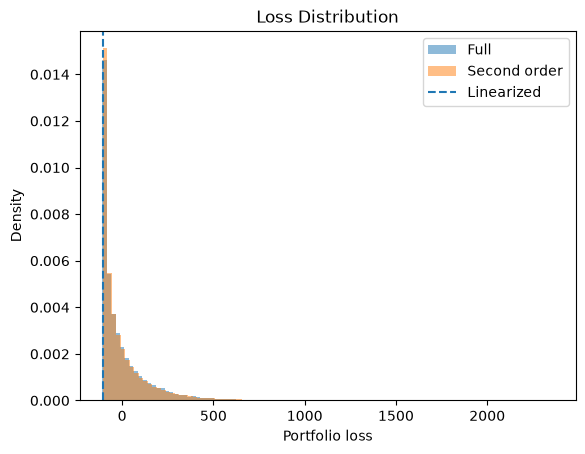

In [ ]:
# Histograms
plt.hist(
    L_full,
    bins=100,
    density=True,
    alpha=0.5,
    label="Full"
)

plt.hist(
    L_second,
    bins=100,
    density=True,
    alpha=0.5,
    label="Second order"
)

plt.axvline(
    L_linear,
    linestyle="--",
    label="Linearized"
)

plt.xlabel("Portfolio loss")
plt.ylabel("Density")
plt.legend()
plt.title("Loss Distribution")
plt.show()